# Level 2 · Task 5: Autocomplete and Autocorrect Data Analytics

**Track:** Data Analytics · Level 2
**Tools:** Python, pandas, numpy, matplotlib, seaborn (everything else is written from scratch)

**Goal:** build and compare text-prediction tools on a real text corpus:

1. **Autocomplete:** predict the next word from the words typed so far (bigram and trigram models).
2. **Autocorrect:** fix misspelled words using edit distance (three different approaches).

Both are evaluated with precision and recall on held-out data, and the notebook ends with a discussion of how far this is from a production keyboard.

> **About the corpus.** The task suggests Project Gutenberg books or a Kaggle text dataset. I wasn't able to download
> anything, so I used the **tweet text from the cleaned election-tweets dataset** (Level 1, Task 3), which is a large
> real-world text corpus (~300k tweets). It is informal, topical (US election, Oct to Nov 2020) and full of
> hashtags and mentions, so the preprocessing step does more work than it would on a book. To use a Gutenberg book
> instead, set `CORPUS_TXT = "your_book.txt"` in the first code cell; nothing else needs to change.
>
> **Why no NLTK / pyspellchecker?** The checklist allows custom Levenshtein logic, and writing the algorithms by hand means the
> notebook needs only pandas, numpy, matplotlib and seaborn, and every step is visible and explainable.

## 1. Setup and corpus

In [1]:
import re, html, math, time, random, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)
sns.set_theme(style="whitegrid")

# ---- settings ----
CORPUS_CSV = "cleaned_election_tweets.csv"   # output of Level 1 Task 3
TEXT_COLUMN = "tweet"
CORPUS_TXT = None        # or e.g. "pride_and_prejudice.txt" to use a Project Gutenberg book instead
SEED = 42
MIN_COUNT = 5            # a word must appear at least this often in the training text to enter the vocabulary

In [2]:
# Common English stopwords (the same idea as NLTK's list, written out so no download is needed)
STOPWORDS = set("""a about above after again against all am an and any are aren't as at be because been before being
below between both but by can can't cannot could couldn't did didn't do does doesn't doing don't down during each few
for from further had hadn't has hasn't have haven't having he he'd he'll he's her here here's hers herself him himself
his how how's i i'd i'll i'm i've if in into is isn't it it's its itself let's me more most mustn't my myself no nor not
of off on once only or other ought our ours ourselves out over own same shan't she she'd she'll she's should shouldn't
so some such than that that's the their theirs them themselves then there there's these they they'd they'll they're
they've this those through to too under until up very was wasn't we we'd we'll we're we've were weren't what what's
when when's where where's which while who who's whom why why's with won't would wouldn't you you'd you'll you're
you've your yours yourself yourselves will just now""".split())

def load_raw_texts():
    if CORPUS_TXT:                                   # a plain text book: split into sentences
        text = open(CORPUS_TXT, encoding="utf-8", errors="ignore").read()
        return pd.Series(re.split(r"(?<=[.!?])\s+|\n{2,}", text))
    return pd.read_csv(CORPUS_CSV, usecols=[TEXT_COLUMN], dtype=str)[TEXT_COLUMN].dropna()

raw_texts = load_raw_texts()
print("Raw texts loaded:", f"{len(raw_texts):,}")

Raw texts loaded: 304,403


## 2. NLP preprocessing

For each text I apply:

1. **Lowercasing** (so `The` and `the` are one word).
2. **Removal of web links, @mentions, hashtags and the `RT` prefix** (they are not words a keyboard should suggest).
3. **Punctuation removal and tokenisation:** a token is a run of letters, optionally with an apostrophe inside
   (`don't`, `it's`). Digits, emojis and symbols are dropped.
4. **Stopword removal:** used **only for the word-frequency analysis**. Autocomplete and autocorrect must keep stopwords,
   because "the", "to" and "of" are exactly the words a keyboard needs to predict, and "teh" must be corrected to "the".

I also keep only texts that look **English** (at least 5 words, almost all Latin letters, and at least 25% stopwords) and **drop identical texts**
(retweets would otherwise count the same sentence many times).

In [3]:
URL = re.compile(r"https?://\S+|www\.\S+")
MENTION = re.compile(r"@\w+")
HASHTAG = re.compile(r"#\w+")
RETWEET = re.compile(r"^rt\b[: ]*", re.I)
TOKEN = re.compile(r"[a-z]+(?:'[a-z]+)?")

def clean_text(s):
    s = html.unescape(s).lower().replace("\u2019", "'")
    s = URL.sub(" ", s); s = MENTION.sub(" ", s); s = HASHTAG.sub(" ", s)
    return RETWEET.sub("", s)

def tokenize(s):
    return TOKEN.findall(clean_text(s))

def remove_stopwords(tokens):
    return [t for t in tokens if t not in STOPWORDS and len(t) > 1]

def latin_ratio(s):
    letters = [c for c in s if c.isalpha()]
    return sum(c.isascii() for c in letters) / len(letters) if letters else 0.0

# Show every step on one real tweet
example = next(t for t in raw_texts if "http" in t and "@" in t and "#" in t and len(t.split()) > 12)
print("RAW      :", example)
print("CLEANED  :", clean_text(example).strip())
print("TOKENS   :", tokenize(example))
print("NO STOPW :", remove_stopwords(tokenize(example)))

RAW      : ►► Tell Politicians to STICK IT with this FREE Item! ►► https://t.co/sua2FPNJTS ►► #2020 #Biden #Deomocrat #Election #Politician #Politics #President #Republican #Trump #VPDebate ►► @FreebieDepot https://t.co/QTRW3eMtd0
CLEANED  : ►► tell politicians to stick it with this free item! ►►   ►►                     ►►
TOKENS   : ['tell', 'politicians', 'to', 'stick', 'it', 'with', 'this', 'free', 'item']
NO STOPW : ['tell', 'politicians', 'stick', 'free', 'item']


In [4]:
kept = []
for s in raw_texts:
    tokens = tokenize(s)
    if len(tokens) < 5 or latin_ratio(s) < 0.95:
        continue
    if sum(t in STOPWORDS for t in tokens) / len(tokens) < 0.25:     # few stopwords -> probably not English
        continue
    kept.append(" ".join(tokens))

texts = list(dict.fromkeys(kept))        # drop identical texts, keep order
funnel = pd.DataFrame({"texts": [len(raw_texts), len(kept), len(texts)]},
                      index=["raw", "English-looking, >= 5 words", "after removing identical texts"])
funnel["% of raw"] = (funnel["texts"] / len(raw_texts) * 100).round(1)
funnel

                                 texts  % of raw
raw                             304403     100.0
English-looking, >= 5 words     167134      54.9
after removing identical texts  159567      52.4

In [5]:
# 80 / 20 split by text: build the models on 'train', measure them on unseen 'test' texts
random.Random(SEED).shuffle(texts)
cut = int(len(texts) * 0.8)
train_texts, test_texts = texts[:cut], texts[cut:]

word_counts = collections.Counter(w for s in train_texts for w in s.split())
print(f"Training texts: {len(train_texts):,} | test texts: {len(test_texts):,}")
print(f"Training words: {sum(word_counts.values()):,} | distinct words: {len(word_counts):,}")
print(f"Words seen at least {MIN_COUNT} times (the vocabulary): {sum(c >= MIN_COUNT for c in word_counts.values()):,}")

Training texts: 127,653 | test texts: 31,914
Training words: 2,752,330 | distinct words: 49,348
Words seen at least 5 times (the vocabulary): 15,590


**Observations**

- Of **304,403** raw tweets, **167,134 (54.9%)** survive the "English-looking, at least 5 words" filter, and **159,567 (52.4%)** remain after removing identical texts. The ~45% that were dropped are very short, mostly hashtags and links, or not in English. The 7,567 identical texts removed (4.5%) are mostly retweets, which would otherwise count the same sentence many times.
- The preprocessing example shows the pipeline at work: the links, hashtags, mentions and `►` symbols disappear, leaving 9 tokens, and stopword removal then keeps only 5 content words (`tell politicians stick free item`).
- The split is **127,653 training texts** and **31,914 unseen test texts**. The training text has **2.75 million words** and 49,348 distinct words, but only **15,590 of them appear at least 5 times**. That small set still covers about 98% of all word occurrences, so the rest is a long tail of names, typos and slang.

## 3. Most frequent words

Top 10 words WITH stopwords: ['the', 'to', 'a', 'and', 'is', 'of', 'in', 'for', 'you', 'i']


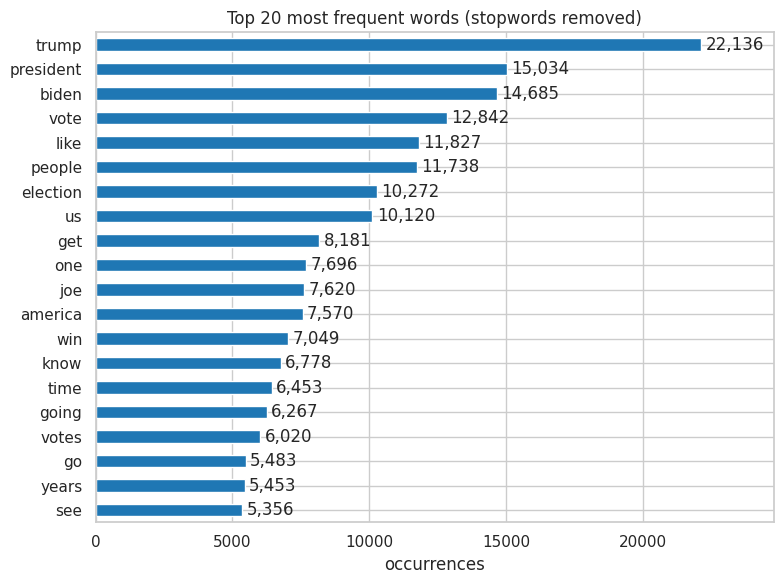

In [6]:
content_counts = collections.Counter(w for s in texts for w in remove_stopwords(s.split()))
top20 = pd.Series(dict(content_counts.most_common(20))).sort_values()

ax = top20.plot.barh(figsize=(8, 6), color="tab:blue")
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)
ax.set_xlabel("occurrences"); ax.set_title("Top 20 most frequent words (stopwords removed)")
ax.set_xlim(0, top20.max() * 1.12)
plt.tight_layout(); plt.show()

all_counts = collections.Counter(w for s in texts for w in s.split())
print("Top 10 words WITH stopwords:", [w for w, _ in all_counts.most_common(10)])

**Observations**

- The most frequent content words are dominated by the election: **trump (22,136), president (15,034), biden (14,685), vote (12,842), election (10,272)**, followed by `joe`, `america`, `win` and `votes`. Everyday words such as `like`, `people`, `get` and `know` fill in between.
- With stopwords left in, the top words are just `the, to, a, and, is, of`, which is why stopword removal is needed for a *frequency analysis* like this chart but must **not** be used for prediction: those are exactly the words a keyboard has to suggest.
- This also shows the corpus bias: the model will learn the language of the 2020 election, not of English in general.

## 4. Autocomplete: next-word prediction with n-grams

**Idea.** An *n-gram* model predicts the next word from the previous *n-1* words, using nothing but counts from the training text:

- **Bigram:** given the last word, suggest the words that most often followed it. `vote` -> `for`, `by`, `in`...
- **Trigram with backoff:** given the last **two** words, suggest what most often followed that pair. If the pair was never seen,
  *back off* to the bigram, and then to the most common words overall. More context gives sharper predictions, but pairs are seen much less often, hence the backoff.
- **Unigram baseline:** always suggest the 3 most frequent words. Any real model should beat this.

**Details.** Words seen fewer than 5 times become `<unk>` (a model cannot learn from one sighting). Every text is padded with start markers so the *first* word of a text can be predicted too. Trigrams seen only once are dropped, which saves memory and removes noise.

In [7]:
BOS, EOS, UNK = "<s>", "</s>", "<unk>"
SPECIAL = {BOS, EOS, UNK}
vocab = {w for w, c in word_counts.items() if c >= MIN_COUNT}

def to_tokens(text):
    return [BOS, BOS] + [w if w in vocab else UNK for w in text.split()] + [EOS]

unigram, bigram_counts, trigram_counts = collections.Counter(), collections.Counter(), collections.Counter()
for text in train_texts:
    t = to_tokens(text)
    unigram.update(t[2:])
    bigram_counts.update(zip(t[1:-1], t[2:]))
    trigram_counts.update(zip(t[:-2], t[1:-1], t[2:]))

def build_topk(counts, k=5, min_count=1):
    # {context tuple: [k most frequent next words]}
    grouped = collections.defaultdict(list)
    for key, c in counts.items():
        if c >= min_count and key[-1] not in SPECIAL:
            grouped[key[:-1]].append((c, key[-1]))
    return {ctx: [w for _, w in sorted(v, key=lambda x: (-x[0], x[1]))[:k]] for ctx, v in grouped.items()}

top_bi = build_topk(bigram_counts, min_count=2)
top_tri = build_topk(trigram_counts, min_count=2)
top_uni = [w for w, _ in unigram.most_common(50) if w not in SPECIAL][:5]

print(f"Bigram contexts: {len(top_bi):,} | trigram contexts (seen >= 2 times): {len(top_tri):,}")
print("Most common words overall (the unigram baseline):", top_uni[:3])

Bigram contexts: 12,206 | trigram contexts (seen >= 2 times): 81,350
Most common words overall (the unigram baseline): ['the', 'to', 'a']


In [8]:
def suggest(prefix, k=3, model="trigram"):
    # Suggest k next words for the text typed so far.
    words = [w if w in vocab else UNK for w in prefix.lower().split()]
    ctx = [BOS, BOS] + words
    out = []
    if model == "trigram":
        out += top_tri.get(tuple(ctx[-2:]), [])
    if model in ("trigram", "bigram"):
        out += top_bi.get((ctx[-1],), [])
    out += top_uni
    return list(dict.fromkeys(out))[:k]          # remove repeats, keep order

prefixes = ["", "i think", "the election", "vote for", "mail in", "make america", "joe", "donald trump is",
            "we need to", "thank you", "stop the", "count every", "get out and", "this is a", "four more"]
demo = pd.DataFrame({
    "typed so far": [p if p else "(start of text)" for p in prefixes],
    "bigram top 3": [", ".join(suggest(p, 3, "bigram")) for p in prefixes],
    "trigram top 3": [", ".join(suggest(p, 3, "trigram")) for p in prefixes],
})
demo

       typed so far          bigram top 3           trigram top 3
0   (start of text)            i, the, is              i, the, is
1           i think      that, the, about           the, it's, we
2      the election          is, day, and        is, and, results
3          vote for           the, a, you          him, trump, is
4           mail in           the, a, his  ballots, votes, ballot
5      make america        is, great, and          great, a, safe
6               joe    biden, is, biden's      biden, is, biden's
7   donald trump is           a, the, not           a, the, going
8        we need to          be, the, get           be, know, get
9         thank you        are, have, can            for, to, and
10         stop the   election, world, us   count, counting, vote
11      count every    time, vote, single     vote, ballot, legal
12      get out and           the, his, i           vote, the, in
13        this is a  lot, good, president       vote, good, great
14        

In [9]:
# Typing a word partway ("elec...") is the other half of autocomplete: complete the word from its first letters
dictionary_by_freq = [w for w, _ in word_counts.most_common() if w in vocab and w.isalpha()]

def complete_word(letters, k=3):
    return [w for w in dictionary_by_freq if w.startswith(letters) and w != letters][:k]

for letters in ["elec", "pres", "demo", "repub", "vot", "cong", "ballo"]:
    print(f"{letters:6s} ->", complete_word(letters))

elec   -> ['election', 'elected', 'elect']
pres   -> ['president', 'presidential', 'presidency']
demo   -> ['democracy', 'democrats', 'democratic']
repub  -> ['republicans', 'republican', 'republic']
vot    -> ['vote', 'votes', 'voting']
cong   -> ['congratulations', 'congrats', 'congress']
ballo  -> ['ballots', 'ballot', 'balloon']


**Observations**

- **The trigram suggestions are clearly sharper than the bigram ones.** For `mail in`, the bigram only sees `in` and offers `the, a, his`, while the trigram knows the pair and offers **`ballots, votes, ballot`**. For `thank you`, the bigram suggests `are, have, can`, but the trigram gives `for, to, and`.
- Other trigram results reflect real slogans in the data: `make america` -> **great**, `stop the` -> **count, counting**, `four more` -> **years**, `count every` -> **vote**.
- Where the context is rare the model gets noisy: `four more` also suggests `wheels`, which shows what a model does with very few examples.
- The word-completion helper works as expected: `elec` -> election, `pres` -> president, `ballo` -> ballots.
- These predictions are specific to this corpus. A model trained on novels would answer `stop the` very differently.

### Autocomplete metrics

For each position in the **unseen test texts**, the model sees the words before it and suggests 3 words; the real next word is the answer.
Only positions whose true next word is in the vocabulary are scored (a model cannot be expected to predict a word it has never seen).

- **Top-1 accuracy:** how often the first suggestion is the right word.
- **Recall@3** ("hit rate"): the share of positions where the right word is **among the 3 suggestions**. This is the number that matters for a keyboard, because the user sees all three.
- **Precision@3:** of all suggestions shown, the share that were right (hits / (3 × positions)). It is capped at one third by design, since only one word can be right per position, so use it to compare models rather than read it as an absolute score.
- **Context coverage:** how often the model had seen the typed context before (rather than falling back to generic frequent words).

In [10]:
# Build the evaluation set: (last two words, true next word) for positions in the unseen test texts
positions = []
for text in test_texts:
    t = to_tokens(text)
    for i in range(2, len(t) - 1):             # i-th word; skip the end marker
        if t[i] not in SPECIAL:                # the true next word must be a vocabulary word
            positions.append((t[i - 2], t[i - 1], t[i]))
print(f"Scorable positions in test texts: {len(positions):,}")

random.Random(SEED).shuffle(positions)
eval_positions = positions[:50_000]            # a random 50,000 keeps the notebook fast

def evaluate_autocomplete(model):
    top1 = hits3 = covered = 0
    start = time.perf_counter()
    for w1, w2, target in eval_positions:
        if model == "unigram":
            sug = top_uni[:3]; has_ctx = False
        elif model == "bigram":
            has_ctx = (w2,) in top_bi
            sug = list(dict.fromkeys(top_bi.get((w2,), []) + top_uni))[:3]
        else:
            has_ctx = (w1, w2) in top_tri
            sug = list(dict.fromkeys(top_tri.get((w1, w2), []) + top_bi.get((w2,), []) + top_uni))[:3]
        top1 += sug[0] == target
        hits3 += target in sug
        covered += has_ctx
    n = len(eval_positions)
    ms = (time.perf_counter() - start) / n * 1000
    return {"model": model, "top-1 accuracy": top1 / n, "recall@3": hits3 / n,
            "precision@3": hits3 / (3 * n), "context coverage": covered / n, "ms per suggestion": ms}

ac_results = pd.DataFrame([evaluate_autocomplete(m) for m in ["unigram", "bigram", "trigram"]]).set_index("model")
ac_results.round(4)

Scorable positions in test texts: 676,082


         top-1 accuracy  recall@3  precision@3  context coverage  ms per suggestion
model                                                                              
unigram          0.0459    0.0972       0.0324            0.0000             0.0007
bigram           0.1339    0.2307       0.0769            0.9916             0.0024
trigram          0.1690    0.2753       0.0918            0.6871             0.0044

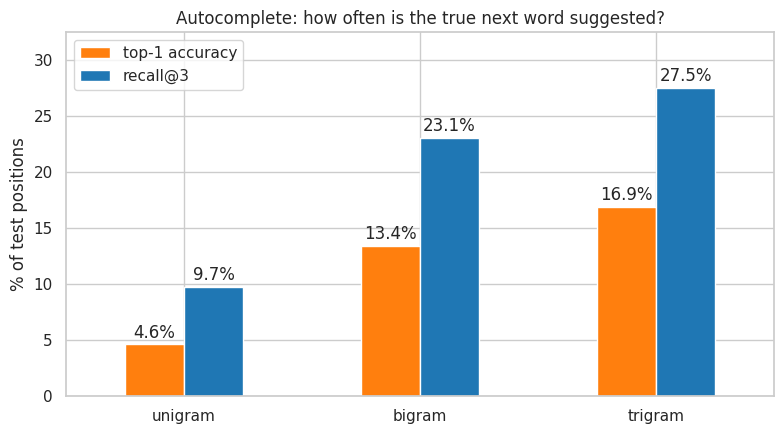

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = ac_results[["top-1 accuracy", "recall@3"]] * 100
plot_df.plot.bar(ax=ax, color=["tab:orange", "tab:blue"], rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=2)
ax.set_ylabel("% of test positions"); ax.set_xlabel("")
ax.set_title("Autocomplete: how often is the true next word suggested?")
ax.set_ylim(0, plot_df.values.max() * 1.18)
plt.tight_layout(); plt.show()

**Observations**

| model | top-1 | recall@3 | precision@3 | context seen before |
|---|---|---|---|---|
| unigram baseline | 4.6% | 9.7% | 3.2% | n/a |
| bigram | 13.4% | 23.1% | 7.7% | 99.2% |
| **trigram + backoff** | **16.9%** | **27.5%** | **9.2%** | 68.7% |

- **Context helps a lot:** the bigram more than doubles the baseline's recall@3 (9.7% -> 23.1%), and the trigram adds another 4.4 points (27.5%).
- **The trade-off is coverage:** a one-word context has been seen in 99.2% of cases, but a two-word context only in **68.7%**. The other 31% fall back to the bigram, which is why backoff is needed.
- The absolute numbers look modest, but next-word prediction is genuinely open-ended: many different words would be fine at most positions, and the model is scored on exactly one. The corpus is also small (2.75M words), informal, and has had hashtags and mentions removed, which leaves gaps in sentences. Precision@3 can never exceed 33% (only one of three suggestions can be right), so it is best used to compare models.
- All three models are effectively instant (under 0.01 ms per suggestion).
- Scored on a random 50,000 of the 676,082 scorable positions in texts the models never saw.

## 5. Autocorrect: fixing misspelled words

**Idea.** If a typed word is not in the dictionary, replace it with the dictionary word that needs the **fewest edits** to reach it. When several words tie, prefer the more frequent one (a real spelling is much more likely to be a common word).

The **dictionary** is every word seen at least 5 times in the training text (single letters other than `a` and `i` are removed as noise).

I implement and compare three approaches:

| | Method | How it finds candidates |
|---|---|---|
| **A** | **Levenshtein, brute force** | Measures the edit distance from the typo to *every* word of similar length. Edits = insert, delete, substitute. |
| **B** | **Damerau edit candidates (Norvig style)** | *Generates* every string 1 edit away (including swapping two adjacent letters, which counts as **one** edit here), keeps the ones that are real words, and tries 2 edits only if needed. |
| **C** | **B + context** | Same candidates as B, but ties are broken using the **previous word** (bigram probability), not just word frequency. |

The key difference between A and B is the **transposition**: `teh` -> `the` is *two* edits for Levenshtein but *one* for B, and swapped letters are one of the most common typing errors.

In [12]:
ALPHABET = "abcdefghijklmnopqrstuvwxyz'"
dictionary = {w: c for w, c in word_counts.items() if w in vocab and (len(w) > 1 or w in ("a", "i"))}
dictionary_by_length = collections.defaultdict(list)
for w in dictionary:
    dictionary_by_length[len(w)].append(w)
total_words = sum(dictionary.values())
print("Dictionary size:", f"{len(dictionary):,}", "words")

# ---------- Approach A: Levenshtein distance (dynamic programming), stops early once the distance exceeds max_dist
def levenshtein(a, b, max_dist=2):
    if abs(len(a) - len(b)) > max_dist:
        return max_dist + 1
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i] + [0] * len(b)
        row_min = i
        for j, cb in enumerate(b, 1):
            cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb))
            row_min = min(row_min, cur[j])
        if row_min > max_dist:
            return max_dist + 1
        prev = cur
    return prev[-1]

def candidates_levenshtein(word, max_dist=2):
    best, best_d = [], max_dist + 1
    for length in range(len(word) - max_dist, len(word) + max_dist + 1):
        for w in dictionary_by_length.get(length, []):
            d = levenshtein(word, w, max_dist)
            if d < best_d:
                best, best_d = [w], d
            elif d == best_d and d <= max_dist:
                best.append(w)
    return (set(best), best_d) if best_d <= max_dist else (set(), None)

# ---------- Approach B: generate all strings one edit away (delete, swap neighbours, replace, insert)
def edits1(word):
    splits = [(word[:i], word[i:]) for i in range(len(word) + 1)]
    deletes = [L + R[1:] for L, R in splits if R]
    swaps = [L + R[1] + R[0] + R[2:] for L, R in splits if len(R) > 1]
    replaces = [L + c + R[1:] for L, R in splits if R for c in ALPHABET]
    inserts = [L + c + R for L, R in splits for c in ALPHABET]
    return set(deletes + swaps + replaces + inserts)

def candidates_norvig(word):
    if word in dictionary:
        return {word}, 0
    e1 = {w for w in edits1(word) if w in dictionary}
    if e1:
        return e1, 1
    e2 = {w2 for w1 in edits1(word) for w2 in edits1(w1) if w2 in dictionary}
    return (e2, 2) if e2 else (set(), None)

def pick_most_frequent(cands, word):
    return max(cands, key=lambda w: (dictionary[w], w)) if cands else word    # no candidate: leave the word alone

def correct_levenshtein(word):
    return pick_most_frequent(candidates_levenshtein(word)[0], word) if word not in dictionary else word

def correct_norvig(word):
    return pick_most_frequent(candidates_norvig(word)[0], word)

# ---------- Approach C: same candidates as B, ranked with the previous word as context
context_total = collections.Counter()
for (prev_w, _), c in bigram_counts.items():
    context_total[prev_w] += c

def correct_context(word, prev_word):
    cands, _ = candidates_norvig(word)
    if not cands:
        return word
    prev = prev_word if prev_word in vocab or prev_word == BOS else UNK
    def score(c):
        p_bigram = bigram_counts.get((prev, c), 0) / max(context_total[prev], 1)
        p_unigram = dictionary[c] / total_words
        return (0.7 * p_bigram + 0.3 * p_unigram, c)
    return max(cands, key=score) if len(cands) > 1 else next(iter(cands))

for typo in ["teh", "recieve", "elction", "wich"]:
    print(f"{typo:10s} Levenshtein -> {correct_levenshtein(typo):12s} Damerau/Norvig -> {correct_norvig(typo)}")

Dictionary size: 15,566 words
teh        Levenshtein -> th           Damerau/Norvig -> the
recieve    Levenshtein -> recieved     Damerau/Norvig -> receive
elction    Levenshtein -> election     Damerau/Norvig -> election
wich       Levenshtein -> with         Damerau/Norvig -> with


### Test 1: 30 deliberately misspelled words

These are realistic mistakes people actually make (swapped letters, missing letters, doubled letters, wrong vowels).
Words that cannot be tested fairly are left out and listed: either the correct spelling is missing from the dictionary, or the misspelling itself is so common in the corpus that the dictionary accepts it as a real word.

In [13]:
manual = {
    "recieve": "receive", "definately": "definitely", "seperate": "separate", "goverment": "government",
    "elction": "election", "presidnet": "president", "demcrat": "democrat", "republcian": "republican",
    "tommorow": "tomorrow", "wich": "which", "becuase": "because", "adress": "address",
    "beleive": "believe", "freind": "friend", "occured": "occurred", "necesary": "necessary",
    "untill": "until", "calender": "calendar", "peice": "piece", "thier": "their",
    "teh": "the", "wierd": "weird", "buisness": "business", "carefull": "careful",
    "enviroment": "environment", "foriegn": "foreign", "truely": "truly", "gaurd": "guard",
    "campain": "campaign", "senater": "senator", "citzen": "citizen", "ballott": "ballot",
}
usable = {k: v for k, v in manual.items() if v in dictionary and k not in dictionary}
typo_in_dict = [k for k in manual if k in dictionary]
truth_missing = [v for k, v in manual.items() if v not in dictionary]
print(f"Usable test words: {len(usable)} of {len(manual)}")
print("Left out because the MISSPELLING itself appears 5+ times in the corpus, so the dictionary treats it as a real word:", typo_in_dict)
print("Left out because the correct word is not in the dictionary:", truth_missing)

rows = []
for typo, truth in usable.items():
    a, b = correct_levenshtein(typo), correct_norvig(typo)
    rows.append({"misspelled": typo, "should be": truth, "A: Levenshtein": a, "B: Damerau": b,
                 "A ok": a == truth, "B ok": b == truth})
manual_df = pd.DataFrame(rows)
print(f"\nAccuracy: A (Levenshtein) = {manual_df['A ok'].mean():.0%} | B (Damerau/Norvig) = {manual_df['B ok'].mean():.0%}")
manual_df

Usable test words: 27 of 32
Left out because the MISSPELLING itself appears 5+ times in the corpus, so the dictionary treats it as a real word: ['goverment', 'tommorow', 'adress', 'untill', 'thier']
Left out because the correct word is not in the dictionary: []

Accuracy: A (Levenshtein) = 63% | B (Damerau/Norvig) = 85%


    misspelled    should be A: Levenshtein   B: Damerau   A ok   B ok
0      recieve      receive       recieved      receive  False   True
1   definately   definitely     definitely   definitely   True   True
2     seperate     separate       separate     separate   True   True
3      elction     election       election     election   True   True
4    presidnet    president      president    president   True   True
5      demcrat     democrat       democrat     democrat   True   True
6   republcian   republican     republican   republican   True   True
7         wich        which           with         with  False  False
8      becuase      because        because      because   True   True
9      beleive      believe         belive      believe  False   True
10      freind       friend           find       friend  False   True
11     occured     occurred       occurred     occurred   True   True
12    necesary    necessary      necessary    necessary   True   True
13    calender     c

**Observations**

- **27 of the 32 words could be tested fairly.** The other 5 (`goverment`, `tommorow`, `adress`, `untill`, `thier`) were left out for a revealing reason: these misspellings appear 5 or more times in the tweets themselves, so the dictionary treats them as real words and the corrector leaves them untouched. **A dictionary learned from informal text inherits that text's typos**, which is a genuine weakness.
- **Accuracy: A (Levenshtein) 63% (17 of 27), B (Damerau/Norvig) 85% (23 of 27).**
- Approach A's extra failures are almost all **swapped letters**: `teh` -> `th`, `recieve` -> `recieved`, `freind` -> `find`, `wierd` -> `wird`, `gaurd` -> `hard`. A swap is *two* edits in Levenshtein but *one* in approach B, so A prefers some other word that is a single edit away. This is the key difference between the two algorithms.
- **Both methods fail on the same 4 words**, for a different reason: `wich` -> with (not *which*), `peice` -> peace (not *piece*), `senater` -> senate (not *senator*), `ballott` -> ballots (not *ballot*). In each case two real words are the same distance away and the more frequent one wins. Frequency alone cannot settle these; context can (approach C).

### Test 2: a larger, systematic test

Thirty hand-picked words is a small sample, so I also build **600 test cases automatically**: take real words from the **unseen test texts** (so common words appear more often, as in real typing),
and damage each one with random typing errors: delete a letter, insert one, replace one, or swap two neighbours.
**480 cases have one error and 120 have two.** Words shorter than 4 letters are skipped (too ambiguous), and only damaged words that are *not* real words are kept.

In [14]:
rng = random.Random(SEED)
LETTERS = "abcdefghijklmnopqrstuvwxyz"

def corrupt(word, n_edits):
    for _ in range(n_edits):
        kind = rng.choice(["delete", "insert", "replace", "swap"])
        i = rng.randrange(len(word))
        if kind == "delete":
            word = word[:i] + word[i + 1:]
        elif kind == "insert":
            word = word[:i] + rng.choice(LETTERS) + word[i:]
        elif kind == "replace":
            word = word[:i] + rng.choice(LETTERS) + word[i + 1:]
        elif i < len(word) - 1 and word[i] != word[i + 1]:
            word = word[:i] + word[i + 1] + word[i] + word[i + 2:]
    return word

# (previous word, real word) pairs from the unseen test texts
pairs = []
for text in test_texts:
    ws = text.split()
    for i, w in enumerate(ws):
        if w in dictionary and w.isalpha() and len(w) >= 4:
            pairs.append((ws[i - 1] if i else BOS, w))
rng.shuffle(pairs)

N_TEST = 600
test_cases = []
for prev_w, truth in pairs:
    n_edits = 1 if len(test_cases) < 0.8 * N_TEST else 2
    typo = corrupt(truth, n_edits)
    if typo != truth and typo not in dictionary and len(typo) >= 2:
        test_cases.append({"prev": prev_w, "truth": truth, "typo": typo, "edits": n_edits})
    if len(test_cases) == N_TEST:
        break
test_df = pd.DataFrame(test_cases)
test_df.head(8)

    prev       truth        typo  edits
0     if        only        owly      1
1     no        more        moer      1
2   line  complicity  comlpicity      1
3  there        once       oncue      1
4  enemy     destroy     deutroy      1
5     of      office      offine      1
6     to        take        tare      1
7    fan        this        thsi      1

In [15]:
# Run the three approaches on the same 600 cases (this takes a couple of minutes: approach A compares each typo with thousands of words)
timing = {}

t0 = time.perf_counter()
test_df["A"] = [correct_levenshtein(w) for w in test_df["typo"]]
timing["A: Levenshtein"] = time.perf_counter() - t0

t0 = time.perf_counter()
test_df["B"] = [correct_norvig(w) for w in test_df["typo"]]
timing["B: Damerau/Norvig"] = time.perf_counter() - t0

t0 = time.perf_counter()
test_df["C"] = [correct_context(w, p) for w, p in zip(test_df["typo"], test_df["prev"])]
timing["C: B + context"] = time.perf_counter() - t0      # includes regenerating candidates

def autocorrect_metrics(col):
    pred = test_df[col]
    correct = int((pred == test_df["truth"]).sum())
    attempted = int((pred != test_df["typo"]).sum())          # the method actually changed the word
    precision = correct / attempted if attempted else 0
    recall = correct / len(test_df)
    return {"accuracy": correct / len(test_df), "precision": precision, "recall": recall,
            "F1": 2 * precision * recall / (precision + recall) if precision + recall else 0,
            "words changed": attempted, "correct fixes": correct}

methods = {"A": "A: Levenshtein", "B": "B: Damerau/Norvig", "C": "C: B + context"}
ac2 = pd.DataFrame({methods[c]: autocorrect_metrics(c) for c in methods}).T
ac2["seconds"] = pd.Series(timing).round(1)
ac2.round(3)

                   accuracy  precision  recall     F1  words changed  correct fixes  seconds
A: Levenshtein        0.693      0.704   0.693  0.699          591.0          416.0     58.8
B: Damerau/Norvig     0.827      0.827   0.827  0.827          600.0          496.0      4.6
C: B + context        0.875      0.875   0.875  0.875          600.0          525.0      4.8

In [16]:
# Accuracy split by how badly the word was damaged
by_edits = pd.DataFrame({methods[c]: (test_df[c] == test_df["truth"]).groupby(test_df["edits"]).mean() for c in methods}).T
by_edits.columns = [f"{n} error(s)" for n in by_edits.columns]
by_edits.round(3)

                   1 error(s)  2 error(s)
A: Levenshtein          0.740       0.508
B: Damerau/Norvig       0.877       0.625
C: B + context          0.923       0.683

**Definitions used above**

- **Precision** = correct fixes ÷ words the method *changed* ("when it changes a word, how often is the change right?").
- **Recall** = correct fixes ÷ all misspelled words ("how many of the typos did it fix correctly?").
- A method that changes nothing it is unsure about has high precision and low recall, so **F1** combines the two.

**Observations**

| approach | accuracy | precision | recall | F1 | time per word |
|---|---|---|---|---|---|
| A: Levenshtein | 69.3% | 70.4% | 69.3% | 69.9% | ~100 ms |
| B: Damerau/Norvig | 82.7% | 82.7% | 82.7% | 82.7% | ~8 ms |
| **C: B + context** | **87.5%** | **87.5%** | **87.5%** | **87.5%** | ~8 ms |

- **B beats A by 13 points and is about 12 times faster.** It builds roughly 500 candidate strings and checks them in the dictionary, instead of comparing the typo with thousands of words.
- **C adds another 4.8 points** (525 correct fixes versus 496 for B) at the same speed, just by using the previous word to choose between equally close candidates.
- Precision equals recall for B and C because they changed all 600 words. A left 9 words untouched (nothing within two Levenshtein edits), so its precision is slightly higher than its recall.
- **Two typing errors in one word are much harder** for every method: accuracy falls from 74.0% to 50.8% for A, from 87.7% to 62.5% for B and from 92.3% to 68.3% for C, a loss of roughly 23 to 25 points.
- Two caveats. C is given the *correct* previous word, whereas in real typing that word may be misspelled too, so its advantage is somewhat optimistic. And the typos here are random, while real ones follow patterns (neighbouring keys, phonetic spelling).

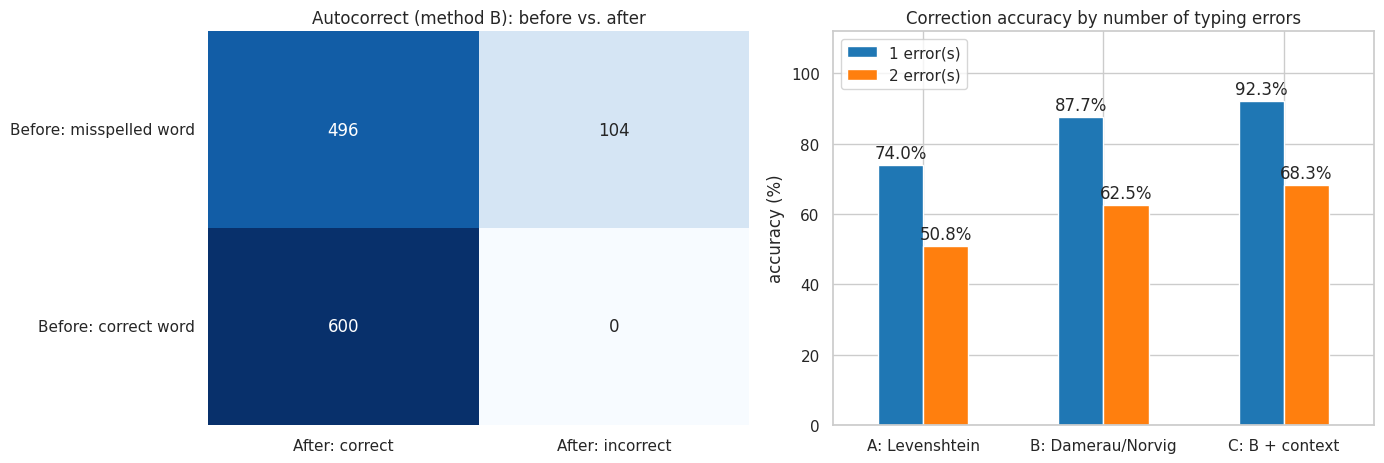

                         After: correct  After: incorrect
Before: misspelled word             496               104
Before: correct word                600                 0

In [17]:
# Confusion matrix (before vs. after) for the best simple method, B, plus a method comparison
best = "B"
n_typo_fixed = int((test_df[best] == test_df["truth"]).sum())
n = len(test_df)
# Real, correct words are never changed because the corrector only touches words missing from the dictionary
kept = sum(1 for w in test_df["truth"] if correct_norvig(w) == w)

cm = pd.DataFrame(
    [[n_typo_fixed, n - n_typo_fixed], [kept, n - kept]],
    index=["Before: misspelled word", "Before: correct word"],
    columns=["After: correct", "After: incorrect"],
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Autocorrect (method B): before vs. after")
axes[0].tick_params(axis="y", rotation=0)

acc_plot = by_edits * 100
acc_plot.plot.bar(ax=axes[1], rot=0, color=["tab:blue", "tab:orange"])
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.1f%%", padding=2)
axes[1].set_ylabel("accuracy (%)"); axes[1].set_ylim(0, 112)
axes[1].set_title("Correction accuracy by number of typing errors")
plt.tight_layout(); plt.show()
cm

**Observations**

- **Left:** of the 600 misspelled words, **496 were fixed correctly (82.7%)** and 104 were not. All 600 correct words stayed unchanged.
- That bottom row is **100% by construction**, because the corrector only touches words missing from the dictionary. The real risks are the reverse cases that this test cannot measure without an outside reference dictionary: valid but rare words (names, new slang) that get "corrected" wrongly, and common typos such as `goverment` that the dictionary accepts.
- **Right:** the same ranking holds for one and for two errors: C > B > A.

In [18]:
# Error analysis: where does method B go wrong?
errors = test_df[test_df["B"] != test_df["truth"]][["typo", "truth", "B", "C", "edits"]].copy()
errors["freq of truth"] = errors["truth"].map(dictionary)
errors["freq of B's pick"] = errors["B"].map(dictionary)
print(f"Method B was wrong on {len(errors)} of {len(test_df)} cases")
print(f"Of those, B picked a MORE frequent word than the true one: {(errors['freq of B' + chr(39) + 's pick'] > errors['freq of truth']).mean():.0%}")
errors.head(10)

Method B was wrong on 104 of 600 cases
Of those, B picked a MORE frequent word than the true one: 79%


     typo   truth      B       C  edits  freq of truth  freq of B's pick
6    tare    take    are    take      1           2796             19186
8     whe    when    the     the      1           6461            122029
16   thre   there    the     the      1           4752            122029
17  tring  trying  thing   thing      1           1635              1852
24  toris  tories  boris   boris      1             21                78
35   ther   there    the     the      1           4752            122029
36   lore    love   more    love      1           2190              8332
45  hould  should  would  should      1           4105              5979
50   thme    them    the    them      1           4065            122029
53  hould  should  would  should      1           4105              5979

**Observations**

- B was wrong on **104 of 600** cases, and in **79%** of them it chose a word that was **more frequent** than the true one. The frequency tie-break is the main source of error.
- The clearest examples are short words, where many real words are one edit away: `whe` -> **the** (122,029 uses) instead of *when* (6,461), `thre` and `ther` -> **the** instead of *there*, `tare` -> *are* instead of *take*, and `hould` -> *would* instead of *should*.
- Context (approach C) fixes some of these (`tare` -> take, `lore` -> love, `hould` -> should, `thme` -> them) but not all: after a short word, `the` is so common that it still wins for `whe`, `thre` and `ther`.
- Short words are the fundamental difficulty. A 3-letter typo has dozens of neighbours, so some uncertainty is unavoidable, and real keyboards respond by showing several options rather than silently choosing one.

## 6. Putting it together: a tiny typing assistant

In [19]:
def typing_assistant(sentence):
    # Fix unknown words one by one (using the previous word as context), then suggest the next word.
    fixed, prev = [], BOS
    for w in sentence.lower().split():
        w = correct_context(w, prev) if w not in dictionary else w
        fixed.append(w); prev = w
    corrected = " ".join(fixed)
    return corrected, suggest(corrected, 3, "trigram")

for s in ["teh presidnet of the", "i beleive we need to", "mail in ballott for", "vote for"]:
    corrected, nxt = typing_assistant(s)
    print(f"typed: {s:28s} -> corrected: {corrected:28s} next word: {nxt}")

typed: teh presidnet of the         -> corrected: the president of the         next word: ['united', 'world', 'us']
typed: i beleive we need to         -> corrected: i believe we need to         next word: ['be', 'know', 'get']
typed: mail in ballott for          -> corrected: mail in ballots for          next word: ['biden', 'a', 'joe']
typed: vote for                     -> corrected: vote for                     next word: ['him', 'trump', 'is']


## 7. Algorithm comparison summary

In [20]:
summary = pd.DataFrame({
    "task": ["autocomplete", "autocomplete", "autocomplete", "autocorrect", "autocorrect", "autocorrect"],
    "approach": ["unigram baseline", "bigram", "trigram + backoff",
                 "A: Levenshtein", "B: Damerau/Norvig", "C: B + context"],
    "main score": [ac_results.loc["unigram", "recall@3"], ac_results.loc["bigram", "recall@3"],
                   ac_results.loc["trigram", "recall@3"],
                   ac2.loc["A: Levenshtein", "accuracy"], ac2.loc["B: Damerau/Norvig", "accuracy"],
                   ac2.loc["C: B + context", "accuracy"]],
    "metric": ["recall@3"] * 3 + ["accuracy"] * 3,
    "speed": [f"{ac_results.loc[m, 'ms per suggestion']:.4f} ms / suggestion" for m in ["unigram", "bigram", "trigram"]]
             + [f"{timing[k] / len(test_df) * 1000:.0f} ms / word" for k in ["A: Levenshtein", "B: Damerau/Norvig", "C: B + context"]],
})
summary["main score"] = (summary["main score"] * 100).round(1).astype(str) + "%"
summary

           task           approach main score    metric                   speed
0  autocomplete   unigram baseline       9.7%  recall@3  0.0007 ms / suggestion
1  autocomplete             bigram      23.1%  recall@3  0.0024 ms / suggestion
2  autocomplete  trigram + backoff      27.5%  recall@3  0.0044 ms / suggestion
3   autocorrect     A: Levenshtein      69.3%  accuracy            98 ms / word
4   autocorrect  B: Damerau/Norvig      82.7%  accuracy             8 ms / word
5   autocorrect     C: B + context      87.5%  accuracy             8 ms / word

**Observations**

- **Autocomplete:** more context is better (unigram 9.7% < bigram 23.1% < trigram 27.5% recall@3), at the cost of needing a backoff for unseen contexts. All three are fast enough for live typing.
- **Autocorrect:** C (87.5%) > B (82.7%) > A (69.3%). B and C are also about 12 times faster than A, and A would get slower still with a bigger dictionary because it compares against every word of similar length.
- **Most suitable for deployment:** the **trigram model with backoff** for next-word prediction and **approach C** for spelling, because it is the most accurate and just as fast as B. Brute-force Levenshtein is the only approach I would rule out on speed alone.

## 8. Limitations compared with a production keyboard such as Google's Gboard

This notebook is a good illustration of how the basic techniques work, but it differs from a production keyboard such as Google's Gboard in several important ways:

1. **Context depth.** Our autocomplete sees only the last two words, and a trigram cannot predict a combination of words it has never seen (31% of our test contexts were unseen). Production keyboards use **neural language models** that read the whole sentence and generalise to new combinations.
2. **Data scale and domain.** We trained on 2.75 million words of election tweets, so our predictions are biased toward that topic. A real keyboard is trained on far more, and far more varied, text, and has to cope with many languages and with switching between them.
3. **The error model.** Ours treats every edit as equally likely and counts only letters. Real keyboards also use **where the finger touched** and which keys are next to each other, plus phonetic and habitual mistakes. They learn from real typing logs rather than from randomly generated typos.
4. **Real-word errors.** We only fix words missing from the dictionary. A mistake that happens to be a valid word (`form` for `from`, `their` for `there`) is invisible to us, and so are typos so common in the corpus that they entered the dictionary (`goverment`).
5. **Personalisation.** A keyboard learns your names, slang and contacts, and does so **on the device** for privacy. We have one static model for everybody.
6. **Confidence and user experience.** A real keyboard decides *whether* to correct at all (low-confidence cases show suggestions instead of silently changing the word) and tracks real-world measures such as how often suggestions are accepted and how many keystrokes they save. Our test only measures whether the "right" word was found.
7. **Engineering.** Production systems answer in a few milliseconds using precomputed indexes (tries, SymSpell-style delete indexes, finite-state transducers) and compressed neural networks. Our approach A, at about 100 ms per word, would be far too slow.

**Conclusion.** Simple counting models already get a long way: the best autocorrect method fixed about 88% of typos and the trigram model had the right word among 3 suggestions about 28% of the time. The remaining gap to a real keyboard is mostly about **context, scale, personalisation and a realistic model of how people actually make mistakes**.